# 05 — Modelagem, Validação e Interpretação (Fase 3)

Lê os artefatos produzidos por `python -m src.modeling.treinar` — não
re-treina (o treino completo leva ~20 minutos: busca de hiperparâmetros,
comparação de 4 candidatos em validação cruzada agrupada, predições
out-of-fold e modelo final). Todos os números abaixo são lidos dos arquivos,
não digitados.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 100

R = json.loads((ROOT / "reports" / "metricas_modelo.json").read_text(encoding="utf-8"))
print("Modelo escolhido:", R["modelo_escolhido"])
print("Critério:", R["criterio_escolha"])
print("Justificativa:", R["justificativa_escolha"])

Modelo escolhido: regressao_logistica
Critério: regra de 1 desvio padrão sobre a ROC-AUC da validação cruzada agrupada por município
Justificativa: mais simples dentro de 1 desvio padrão do melhor (hist_gradient_boosting: 0.6520 ± 0.0168; regressao_logistica: 0.6480)


## 1. O pipeline

Um único `Pipeline` do scikit-learn: pré-processamento + modelo. Tudo que é
aprendido (medianas, categorias, escalas) é aprendido só no treino de cada
fold — nada vaza para validação/teste.

In [2]:
import joblib
modelo = joblib.load(ROOT / "models" / "modelo_final.joblib")
modelo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessador', ...), ('classificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['rede_label','escola_n_alunos','mun_n_alunos_ant',...,'idhm_renda', 'capital_uf','amazonia_legal']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('cont', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By 

## 2. Desenho da validação

In [3]:
print(f"Treino: {R['n_treino']:,} alunos | Teste: {R['n_teste']:,} alunos de {R['n_municipios_teste']:,} municípios NUNCA vistos")
vc = R["validacao_comparada"]
print(f"\nMesma validação cruzada, dois desenhos:")
print(f"  split aleatório por aluno:      ROC-AUC {vc['split_aleatorio_por_aluno']}")
print(f"  split agrupado por município:   ROC-AUC {vc['split_agrupado_por_municipio']}")
print(f"  otimismo do split aleatório:    {vc['otimismo_split_aleatorio']:+.4f}")

Treino: 1,481,522 alunos | Teste: 370,330 alunos de 1,164 municípios NUNCA vistos

Mesma validação cruzada, dois desenhos:
  split aleatório por aluno:      ROC-AUC 0.6513
  split agrupado por município:   ROC-AUC 0.648
  otimismo do split aleatório:    +0.0033


O split agrupado por município é o que mede a pergunta real ("funciona num
município novo?"). A diferença entre os dois desenhos é o quanto um split
aleatório por aluno superestimaria o resultado.

## 3. Busca de hiperparâmetros e comparação de modelos

Melhores configurações do HistGradientBoosting (CV agrupada, 3 folds):


,rank_test_score,mean_test_score,std_test_score,mean_fit_time,params
0,1,0.649738,0.004610,13.190897,"{'classificador__min_samples_leaf': 2000, 'cla..."
1,2,0.648354,0.005484,10.963028,"{'classificador__min_samples_leaf': 2000, 'cla..."
2,3,0.647921,0.005558,9.215086,"{'classificador__min_samples_leaf': 20, 'class..."
3,4,0.647229,0.006394,10.700919,"{'classificador__min_samples_leaf': 20, 'class..."
4,5,0.645010,0.004002,10.727154,"{'classificador__min_samples_leaf': 100, 'clas..."


,cv_roc_auc_medio,cv_roc_auc_desvio,treino_roc_auc_medio,gap_treino_validacao,tempo_fit_medio_s
modelo,,,,,
baseline_prevalencia,0.5000,0.0000,0.5000,0.0000,0.4
regressao_logistica,0.6480,0.0162,0.6515,0.0036,1.3
random_forest,0.6514,0.0150,0.6873,0.0359,11.3
hist_gradient_boosting,0.6520,0.0168,0.6853,0.0333,15.7


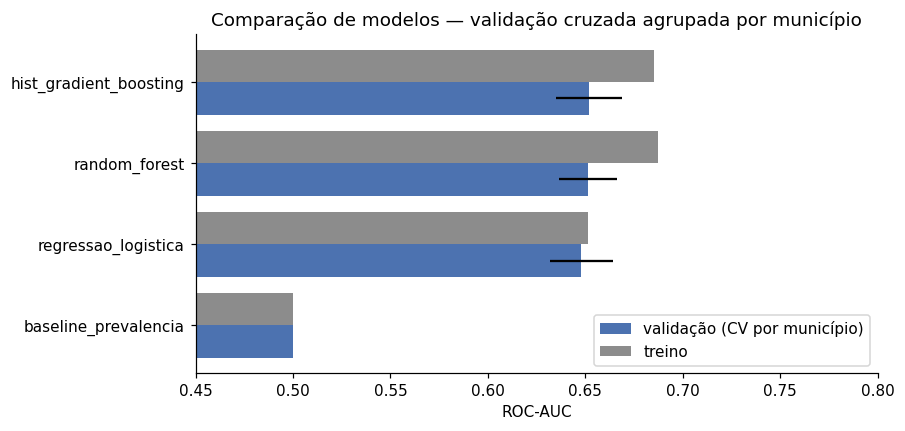

In [4]:
tuning = pd.read_csv(ROOT / "reports" / "tuning_hist_gradient_boosting.csv")
print("Melhores configurações do HistGradientBoosting (CV agrupada, 3 folds):")
display(tuning.head(5))
comparacao = pd.DataFrame(R["comparacao_modelos"]).set_index("modelo")
display(comparacao)
display(Image(filename=str(ROOT / "images" / "04_comparacao_modelos.png")))

Regra de escolha (D14): entre os modelos a até 1 desvio padrão do melhor,
fica o mais simples. Diferenças menores que a variação entre folds não são
evidência de que o modelo mais complexo generaliza melhor — e o gap
treino-validação (coluna `gap_treino_validacao`) mostra quem está mais
perto de overfitting.

## 4. Resultado no teste (municípios nunca vistos)

In [5]:
t, b = R["metricas_teste"], R["metricas_baseline_teste"]
tabela = pd.DataFrame({"modelo": t, "baseline": b}).drop("matriz_confusao")
display(tabela)
print(f"ROC-AUC treino {R['roc_auc_treino']} vs teste {t['roc_auc']} (gap {R['roc_auc_treino'] - t['roc_auc']:.4f})")
print(f"ROC-AUC out-of-fold em TODOS os municípios (5 folds agrupados): {R['roc_auc_oof_todos_alunos']}")

,modelo,baseline
roc_auc,0.6276,0.5
average_precision,0.7081,0.5979
brier,0.2286,0.2404
acuracia,0.6297,0.5979
precisao,0.6458,0.5979
recall,0.8432,1.0
f1,0.7314,0.7484
precisao_risco,0.5726,0.0
recall_risco,0.3124,0.0
f1_risco,0.4042,0.0


ROC-AUC treino 0.6516 vs teste 0.6276 (gap 0.0240)
ROC-AUC out-of-fold em TODOS os municípios (5 folds agrupados): 0.6451


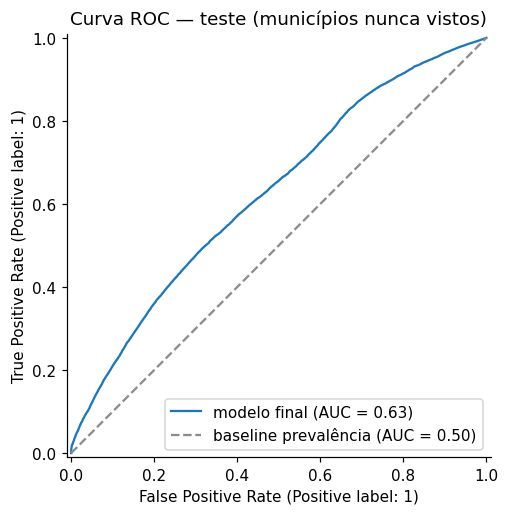

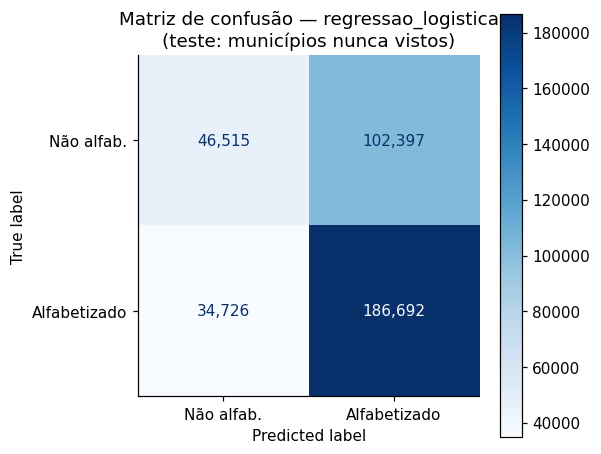

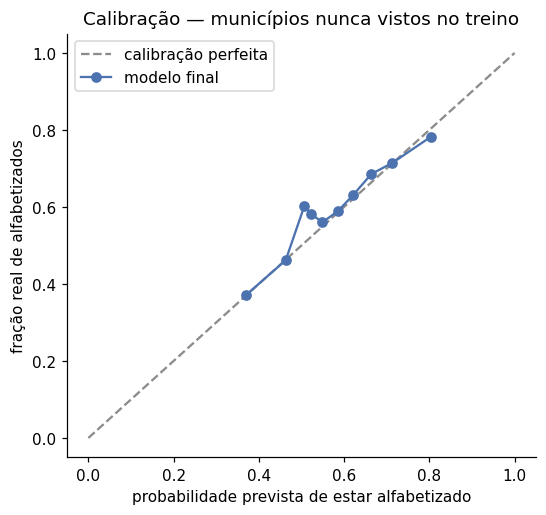

In [6]:
for img in ["06_curva_roc.png", "05_matriz_confusao.png", "07_calibracao.png"]:
    display(Image(filename=str(ROOT / "images" / img)))

Calibração: os pontos perto da diagonal significam que uma probabilidade
prevista de 60% corresponde a ~60% de alfabetizados — condição para somar
probabilidades por município e comparar com metas (notebook 06).

## 5. Uso operacional: priorização em vez de limiar fixo

,fracao_priorizada,limiar_p_risco,taxa_risco_no_grupo,recall_risco,lift
0,0.05,0.6239,0.6559,0.0816,1.631
1,0.10,0.5766,0.6294,0.1565,1.565
2,0.20,0.5086,0.5842,0.2906,1.453
3,0.30,0.4840,0.5216,0.3891,1.297
4,0.50,0.4349,0.4847,0.6027,1.205


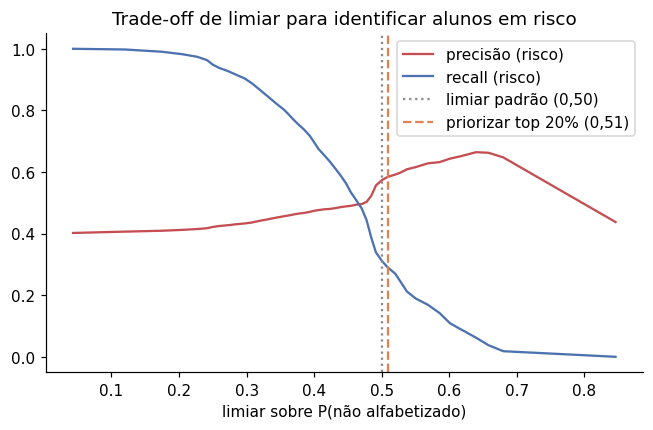

In [7]:
prior = pd.read_csv(ROOT / "reports" / "analise_priorizacao.csv")
display(prior)
display(Image(filename=str(ROOT / "images" / "08_tradeoff_limiar.png")))

Lida linha a linha: se um programa de reforço só pode atender X% dos
alunos, atendendo os X% de maior risco previsto ele encontra a fração
`taxa_risco_no_grupo` de alunos de fato em risco — `lift` vezes mais do que
escolhendo ao acaso.

## 6. Interpretabilidade e teste das hipóteses

,feature,queda_roc_auc,desvio
0,taxa_alfabetizacao_ant,0.072238,0.001821
1,prof_media_ant,0.035340,0.001210
2,participacao_ant,0.004511,0.000294
3,idhm_educacao,0.004383,0.000180
4,meta_ano,0.002470,0.000648
5,idhm_longevidade,0.002204,0.000139
6,nivel_alfabetizacao_ant,0.001639,0.000234
7,prof_desvio_ant,0.001405,0.000156
8,rede_label,0.000948,0.000455
9,esforco_meta,0.000920,0.000180


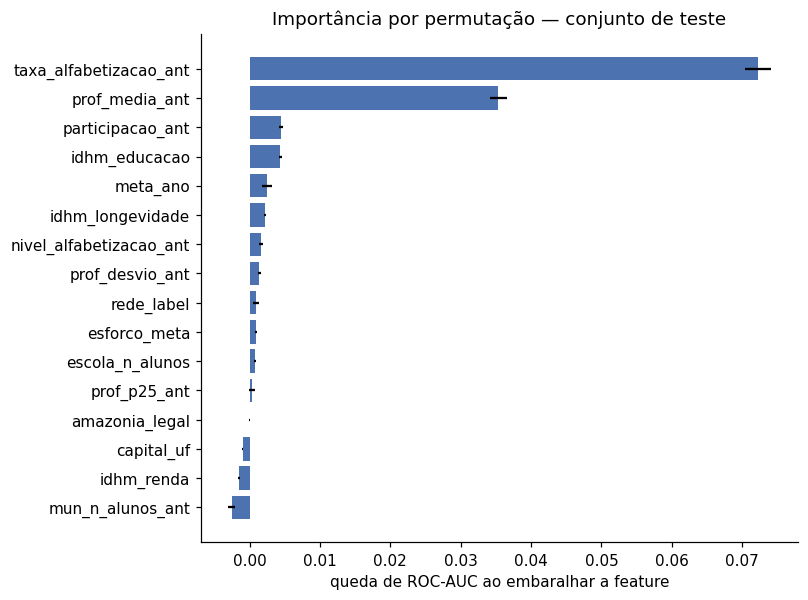

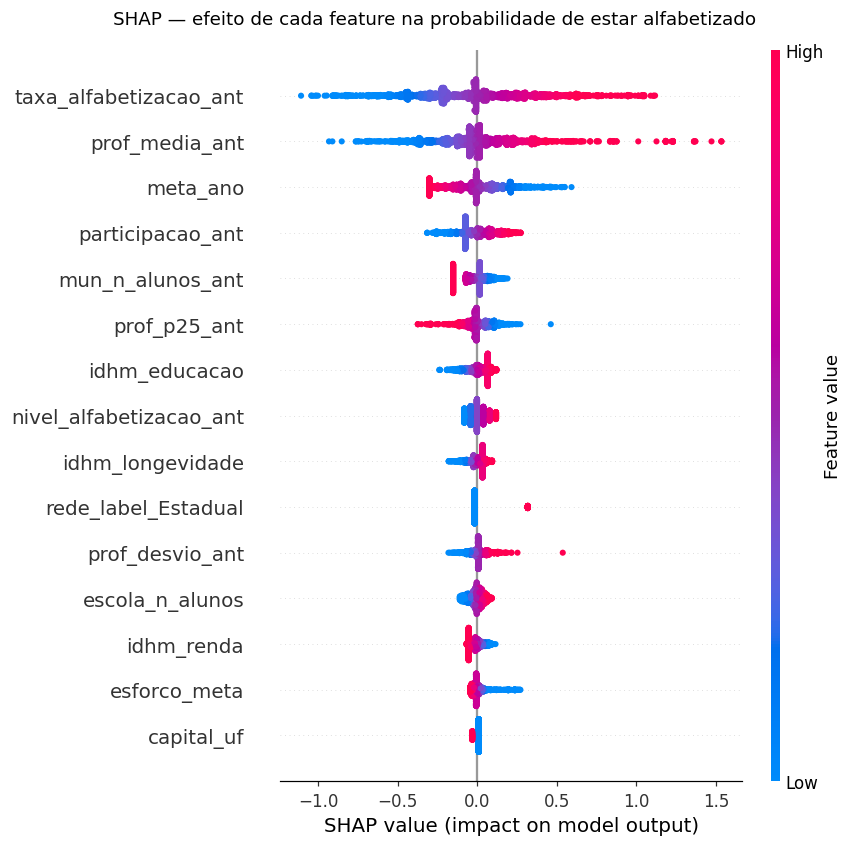

In [8]:
perm = pd.read_csv(ROOT / "reports" / "importancia_permutacao.csv")
shap_imp = pd.read_csv(ROOT / "reports" / "shap_importance.csv")
display(perm.head(10))
display(Image(filename=str(ROOT / "images" / "09_importancia_permutacao.png")))
display(Image(filename=str(ROOT / "images" / "10_shap_summary.png")))

In [9]:
ranking = perm.set_index("feature")["queda_roc_auc"]
educacionais = ["taxa_alfabetizacao_ant", "prof_media_ant", "prof_p25_ant", "nivel_alfabetizacao_ant",
                "participacao_ant", "prof_desvio_ant"]
idhm = ["idhm_educacao", "idhm_renda", "idhm_longevidade"]
print("H1 — feature mais importante:", ranking.idxmax(), f"(queda de ROC-AUC {ranking.max():.4f})")
print(f"H2 — soma da importância: históricos educacionais {ranking[educacionais].sum():.4f} | IDHM {ranking[idhm].sum():.4f}")
coef = pd.Series(modelo.named_steps["classificador"].coef_[0] if hasattr(modelo.named_steps["classificador"], "coef_") else [],
                 dtype=float)
if len(coef):
    nomes = modelo.named_steps["preprocessador"].get_feature_names_out()
    coef.index = [n.split("__", 1)[-1] for n in nomes]
    print(f"H3 — coeficiente de esforco_meta (padronizado): {coef['esforco_meta']:+.4f}")

H1 — feature mais importante: taxa_alfabetizacao_ant (queda de ROC-AUC 0.0722)
H2 — soma da importância: históricos educacionais 0.1155 | IDHM 0.0051
H3 — coeficiente de esforco_meta (padronizado): -0.0638


**H1 — confirmada.** A taxa de alfabetização do município no ano anterior
é, isoladamente, a feature mais importante; a proficiência média do ano
anterior vem em segundo. Juntas respondem pela maior parte da capacidade de
separação do modelo.

**H2 — confirmada, com folga.** A soma da importância dos históricos
educacionais é mais de 20× a dos componentes do IDHM. Isso **não** quer
dizer que condição socioeconômica não importa — ela já está "embutida" no
resultado educacional passado do município. Quer dizer que, para prever o
próximo ano, o histórico educacional carrega quase toda a informação que o
IDHM traria, e mais.

**H3 — confirmada na direção, fraca na magnitude.** O coeficiente de
`esforco_meta` é negativo (mais esforço necessário → menor chance), mas a
contribuição marginal é pequena: a correlação simples de −0,20 vista no
notebook 04 é, em boa parte, explicada pelo próprio resultado passado (quem
precisa de mais esforço é quem teve resultado mais baixo).

Coeficientes da regressão logística são interpretáveis aqui porque as
redundâncias por construção foram removidas (IDHM composto e taxa da rede
municipal — ver D7 em `docs/decisoes_analiticas.md`). Antes disso, o IDHM
saía com coeficiente −1,19 compensando os componentes positivos.

Observação: `mun_n_alunos_ant`, `idhm_renda` e `capital_uf` têm importância
por permutação levemente **negativa** no teste — embaralhá-las melhora a
ROC-AUC em ~0,001–0,003. É um sinal de que não ajudam a generalizar para
municípios novos. Não foram removidas com base nisso, porque seria escolher
features olhando o teste; fica como candidata a seleção de features por
validação cruzada (evolução futura).

**H4** e **H5**: testadas no notebook 06 (agregação municipal e clusters).

## 7. Onde o modelo funciona pior

,nome_regiao,n_alunos,taxa_real,taxa_prevista,roc_auc
0,Sudeste,154743,62.9,57.4,0.5822
1,Norte,28237,51.8,51.0,0.6057
2,Centro-Oeste,24057,67.6,63.6,0.6073
3,Sul,55031,63.1,66.3,0.6141
4,Nordeste,108262,54.0,55.1,0.6675


,rede_label,n_alunos,taxa_real,taxa_prevista,roc_auc
0,Estadual,25890,60.8,64.3,0.5689
1,Municipal,344440,59.7,57.5,0.6316


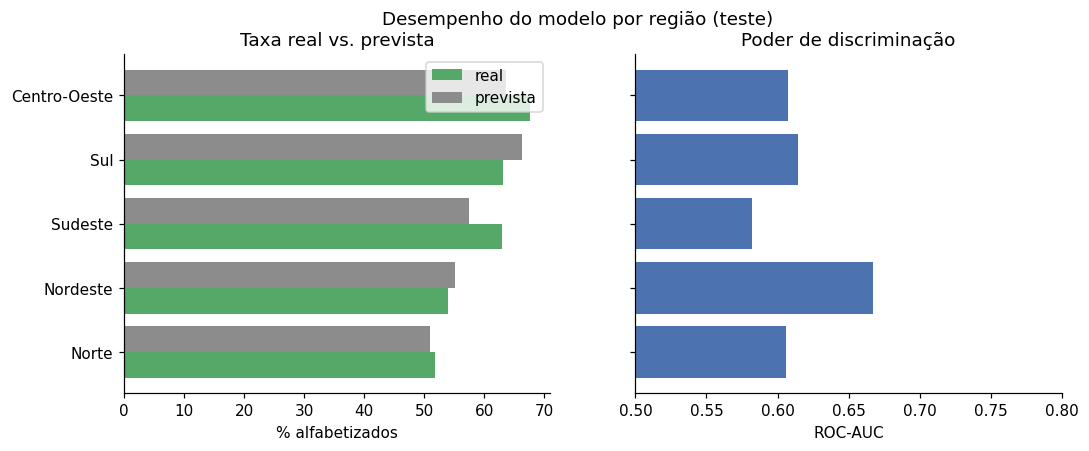

In [10]:
for arquivo in ["desempenho_por_nome_regiao.csv", "desempenho_por_rede_label.csv"]:
    display(pd.read_csv(ROOT / "reports" / arquivo))
display(Image(filename=str(ROOT / "images" / "11_desempenho_regiao.png")))

Diferenças entre taxa real e prevista por região mostram onde o modelo
erra de forma sistemática — como UF/região ficaram fora das features (D8),
um viés regional residual é esperado e é documentado em vez de "corrigido"
com uma variável que não transfere para o ano seguinte.